In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pycbc.noise import noise_from_psd
from pycbc.psd import aLIGOZeroDetHighPower
from pycbc.types import TimeSeries
from scipy.signal import butter, sosfiltfilt

np.random.seed(42)

/home/gopal/miniconda3/envs/gwenv/lib/python3.10/site-packages/pycbc/types/array.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(True)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal as _lal


In [2]:
duration = 104.0       # seconds
fs = 2048             # Hz
dt = 1.0 / fs

# Total number of samples
N = int(duration * fs)

# Frequency resolution
delta_f = 1.0 / duration

# Band-pass frequencies
f_low = 30.0
f_high = 1000.0

print("Duration:", duration, "s")
print("Sampling frequency:", fs, "Hz")
print("Number of samples:", N)
print("delta_t:", dt, "s")
print("delta_f:", delta_f, "Hz")

Duration: 104.0 s
Sampling frequency: 2048 Hz
Number of samples: 212992
delta_t: 0.00048828125 s
delta_f: 0.009615384615384616 Hz


In [3]:
flen = N // 2 + 1
psd = aLIGOZeroDetHighPower(flen, delta_f, low_freq_cutoff=30.0)
freqs = np.arange(len(psd)) * delta_f
print("PSD length:", len(psd))
print("Maximum frequency:", freqs[-1], "Hz")

PSD length: 106497
Maximum frequency: 1024.0 Hz


In [4]:
h1_noise = noise_from_psd(N, dt, psd, seed=300)
l1_noise = noise_from_psd(N, dt, psd, seed=400)

print("H1 samples:", len(h1_noise))
print("L1 samples:", len(l1_noise))
print("H1 duration:", len(h1_noise) * dt, "s")
print("L1 duration:", len(l1_noise) * dt, "s")

H1 samples: 212992
L1 samples: 212992
H1 duration: 104.0 s
L1 duration: 104.0 s


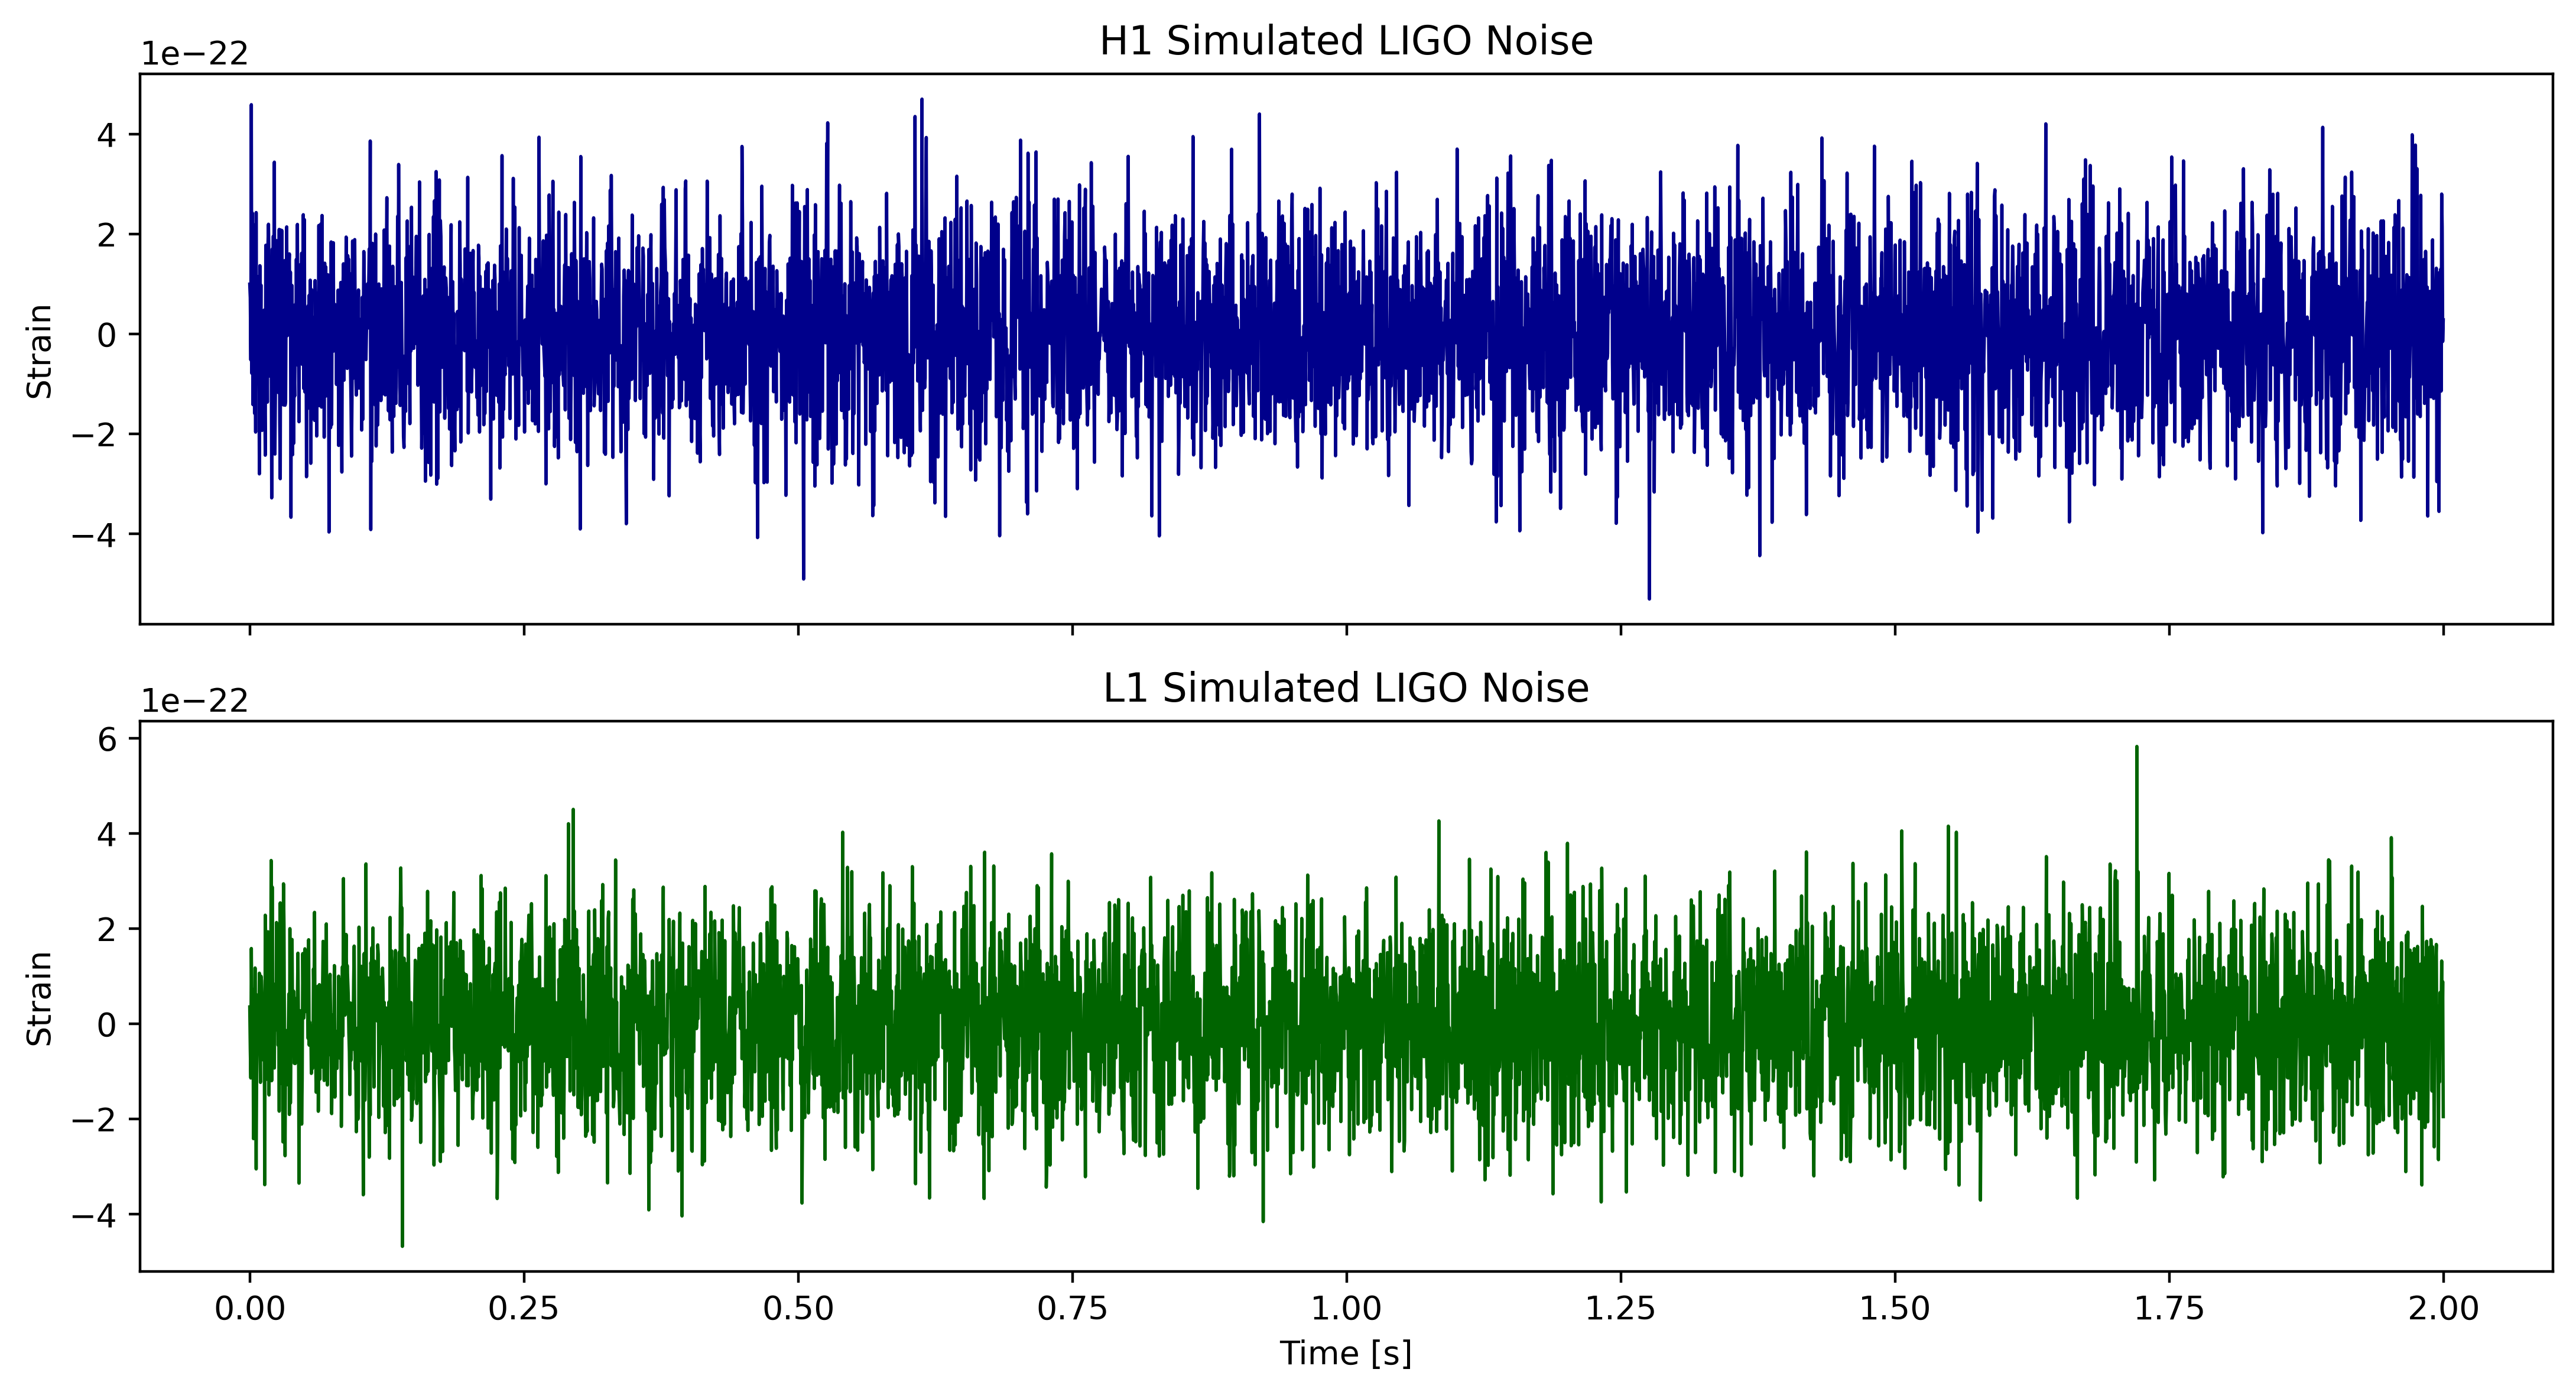

In [5]:
plot_duration = 2.0
nplot = int(plot_duration * fs)
time = np.arange(N) / fs
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True, dpi = 400)

ax[0].plot(time[:nplot],h1_noise.numpy()[:nplot], color = "darkblue",linewidth= 1.0)
ax[0].set_ylabel("Strain")
ax[0].set_title("H1 Simulated LIGO Noise")
ax[1].plot(time[:nplot],l1_noise.numpy()[:nplot],color = "darkgreen",linewidth= 1.0)
ax[1].set_ylabel("Strain")
ax[1].set_xlabel("Time [s]")
ax[1].set_title("L1 Simulated LIGO Noise")

plt.tight_layout()
plt.show()

## The Sine-Gaussian Plus Polarization Waveform

In this cell, we define the sine-Gaussian waveform that will later be injected into white Gaussian noise. 
In this simplified case, we use only the plus-polarization component, but we include a parametrization factor using `alpha` and an overall amplitude scaling.

The basic sine-Gaussian component is written as:

$$
H_+(t) =
\exp\left[-\frac{(t-t_0)^2}{\tau^2}\right]
\sin\left[2\pi f_0 (t-t_0)\right]
$$

where:

- f_0 is the central frequency of the waveform,
- t_0 is the central time of the waveform,
- tau controls the duration of the Gaussian envelope.

The characteristic duration tau is defined as:

$$
\tau = \frac{Q}{\sqrt{2}\pi f_0}
$$

where Q is the quality factor. A larger Q gives a longer waveform with more oscillations, while a smaller Q gives a shorter burst.

In the code, we use a parameterized plus-polarization waveform:

$$
h_+(t) =
A \left( \frac{1+\alpha^2}{2} \right) H_+(t)
$$

Therefore, the final waveform used in the code is:

$$
h_+(t) =
A \left( \frac{1+\alpha^2}{2} \right)
\exp\left[-\frac{(t-t_0)^2}{\tau^2}\right]
\sin\left[2\pi f_0 (t-t_0)\right]
$$

In [6]:
#QsSG = np.array([3, 9, 100])

# Function to calculate the characteristic duration tau
def SG_tau(Q, f0):
    tau = Q / (np.sqrt(2) * np.pi * f0)
    return tau


# Function to generate plus polarization
def SG_waveform(Q, f0, t, alpha, amplitude, shift):
    tau = SG_tau(Q, f0)

    # Central time of the waveform
    t0 = np.max(t) / 2
    t0 = t0 + shift

    # Shifted time coordinate
    tc = t - t0

    # Basic sine-Gaussian components
    H_plus = np.exp(-(tc**2 / tau**2)) * np.sin(2 * np.pi * f0 * tc)
    h_plus = amplitude * ((1 + alpha**2) / 2) * H_plus
   
    return h_plus

In [7]:
from pycbc.types import TimeSeries
from pycbc.psd import aLIGOZeroDetHighPower
from pycbc.filter import sigma

# 1 second time array
times = np.arange(0, 1.0, dt)

# Injection parameters
f0 = 500.0
Q = 100
#Q = QsSG[2]       # Q = 100
alpha = 0.8
target_snr = 15.0

# Generate unit-amplitude sine-Gaussian
SG_base = SG_waveform(Q,f0,times,alpha,amplitude=1.0,shift=0.0)

# Convert to PyCBC TimeSeries
SG_ts = TimeSeries(SG_base, delta_t=dt)

# Frequency resolution for a 1-second waveform
delta_f_sg = 1.0 / SG_ts.duration

# PSD sampled at the same frequency resolution as the SG
psd_sg = aLIGOZeroDetHighPower(len(SG_ts) // 2 + 1,delta_f_sg,low_freq_cutoff=30.0)

# SNR of the unit-amplitude waveform
snr_unit = sigma(SG_ts,psd=psd_sg,low_frequency_cutoff=30.0,high_frequency_cutoff=1000.0)

# Scale to target SNR = 15
scale_factor = target_snr / snr_unit
SG_scaled = SG_base * scale_factor

# Verify final SNR
SG_scaled_ts = TimeSeries(SG_scaled, delta_t=dt)
snr_final = sigma(SG_scaled_ts,psd=psd_sg,low_frequency_cutoff=30.0,high_frequency_cutoff=1000.0)

print("SG samples:", len(SG_scaled))
print("Unit SG SNR:", snr_unit)
print("Scale factor:", scale_factor)
print("Final SNR:", snr_final)

SG samples: 2048
Unit SG SNR: 5.017468369360064e+22
Scale factor: 2.9895554681719147e-22
Final SNR: 15.0


In [8]:
# Empty 104 seconds injection streams
h1_injection = np.zeros(N)
l1_injection = np.zeros(N)

# Insert one SNR15 SG into each future 1 second testing segment
for i in range(100):
    start_idx = int((2 + i) * fs)
    end_idx = start_idx + fs
    h1_injection[start_idx:end_idx] += SG_scaled
    l1_injection[start_idx:end_idx] += SG_scaled

print("H1 injection length:", len(h1_injection))
print("L1 injection length:", len(l1_injection))
print("H1 injection duration:", len(h1_injection) / fs, "s")
print("L1 injection duration:", len(l1_injection) / fs, "s")

H1 injection length: 212992
L1 injection length: 212992
H1 injection duration: 104.0 s
L1 injection duration: 104.0 s


In [9]:
# Add the injections to the original colored LIGO like noise
h1_signal_noise = h1_noise.numpy() + h1_injection
l1_signal_noise = l1_noise.numpy() + l1_injection

print("H1 signal+noise samples:", len(h1_signal_noise))
print("L1 signal+noise samples:", len(l1_signal_noise))
print("H1 duration:", len(h1_signal_noise) / fs, "s")
print("L1 duration:", len(l1_signal_noise) / fs, "s")

H1 signal+noise samples: 212992
L1 signal+noise samples: 212992
H1 duration: 104.0 s
L1 duration: 104.0 s


In [10]:
def whiten_with_psd(data, psd, fs):
    x = np.asarray(data, dtype=np.float64)
    N = len(x)
    dt = 1.0 / fs

    # FFT
    hf = np.fft.rfft(x)

    # PSD as numpy array
    psd_array = np.asarray(psd)

    # Avoid division by zero
    valid = psd_array > 0
    white_hf = np.zeros_like(hf, dtype=complex)

    # Whiten in frequency domain
    white_hf[valid] = hf[valid] / np.sqrt(psd_array[valid])

    # Back to time domain
    white = np.fft.irfft(white_hf, n=N)

    # Normalize scale
    white *= np.sqrt(2.0 * dt)

    return white

In [11]:
h1_whitened = whiten_with_psd(h1_signal_noise,psd,fs)
l1_whitened = whiten_with_psd(l1_signal_noise,psd,fs)

print("H1 whitened samples:", len(h1_whitened))
print("L1 whitened samples:", len(l1_whitened))
print("H1 duration:", len(h1_whitened) / fs, "s")
print("L1 duration:", len(l1_whitened) / fs, "s")

H1 whitened samples: 212992
L1 whitened samples: 212992
H1 duration: 104.0 s
L1 duration: 104.0 s


In [12]:
def bandpass_filter(data, fs, lowcut=30.0, highcut=1000.0, order=4):
    sos = butter(order,[lowcut, highcut],btype="bandpass",fs=fs,output="sos")
    filtered = sosfiltfilt(sos, data)

    return filtered

In [13]:
h1_whitened_bp = bandpass_filter(h1_whitened,fs,lowcut=f_low,highcut=f_high)
l1_whitened_bp = bandpass_filter(l1_whitened,fs,lowcut=f_low,highcut=f_high)

print("H1 final shape:", h1_whitened_bp.shape)
print("L1 final shape:", l1_whitened_bp.shape)
print("H1 duration:", len(h1_whitened_bp) / fs, "s")
print("L1 duration:", len(l1_whitened_bp) / fs, "s")

H1 final shape: (212992,)
L1 final shape: (212992,)
H1 duration: 104.0 s
L1 duration: 104.0 s


In [14]:
# Remove 2 seconds from the beginning and end
trim_seconds = 2
trim_samples = int(trim_seconds * fs)
h1_trimmed = h1_whitened_bp[trim_samples:-trim_samples]
l1_trimmed = l1_whitened_bp[trim_samples:-trim_samples]

print("Samples removed from each edge:", trim_samples)
print("H1 trimmed samples:", len(h1_trimmed))
print("L1 trimmed samples:", len(l1_trimmed))
print("H1 trimmed duration:", len(h1_trimmed) / fs, "s")
print("L1 trimmed duration:", len(l1_trimmed) / fs, "s")

Samples removed from each edge: 4096
H1 trimmed samples: 204800
L1 trimmed samples: 204800
H1 trimmed duration: 100.0 s
L1 trimmed duration: 100.0 s


In [15]:
# Split 100 seconds streams into 100 one second segments
samples_per_file = fs   # 2048 samples = 1 second

H1_segments = h1_trimmed.reshape(100, samples_per_file)
L1_segments = l1_trimmed.reshape(100, samples_per_file)

print("H1 segments shape:", H1_segments.shape)
print("L1 segments shape:", L1_segments.shape)
print("Samples in each H1 file:", H1_segments.shape[1])
print("Samples in each L1 file:", L1_segments.shape[1])

H1 segments shape: (100, 2048)
L1 segments shape: (100, 2048)
Samples in each H1 file: 2048
Samples in each L1 file: 2048


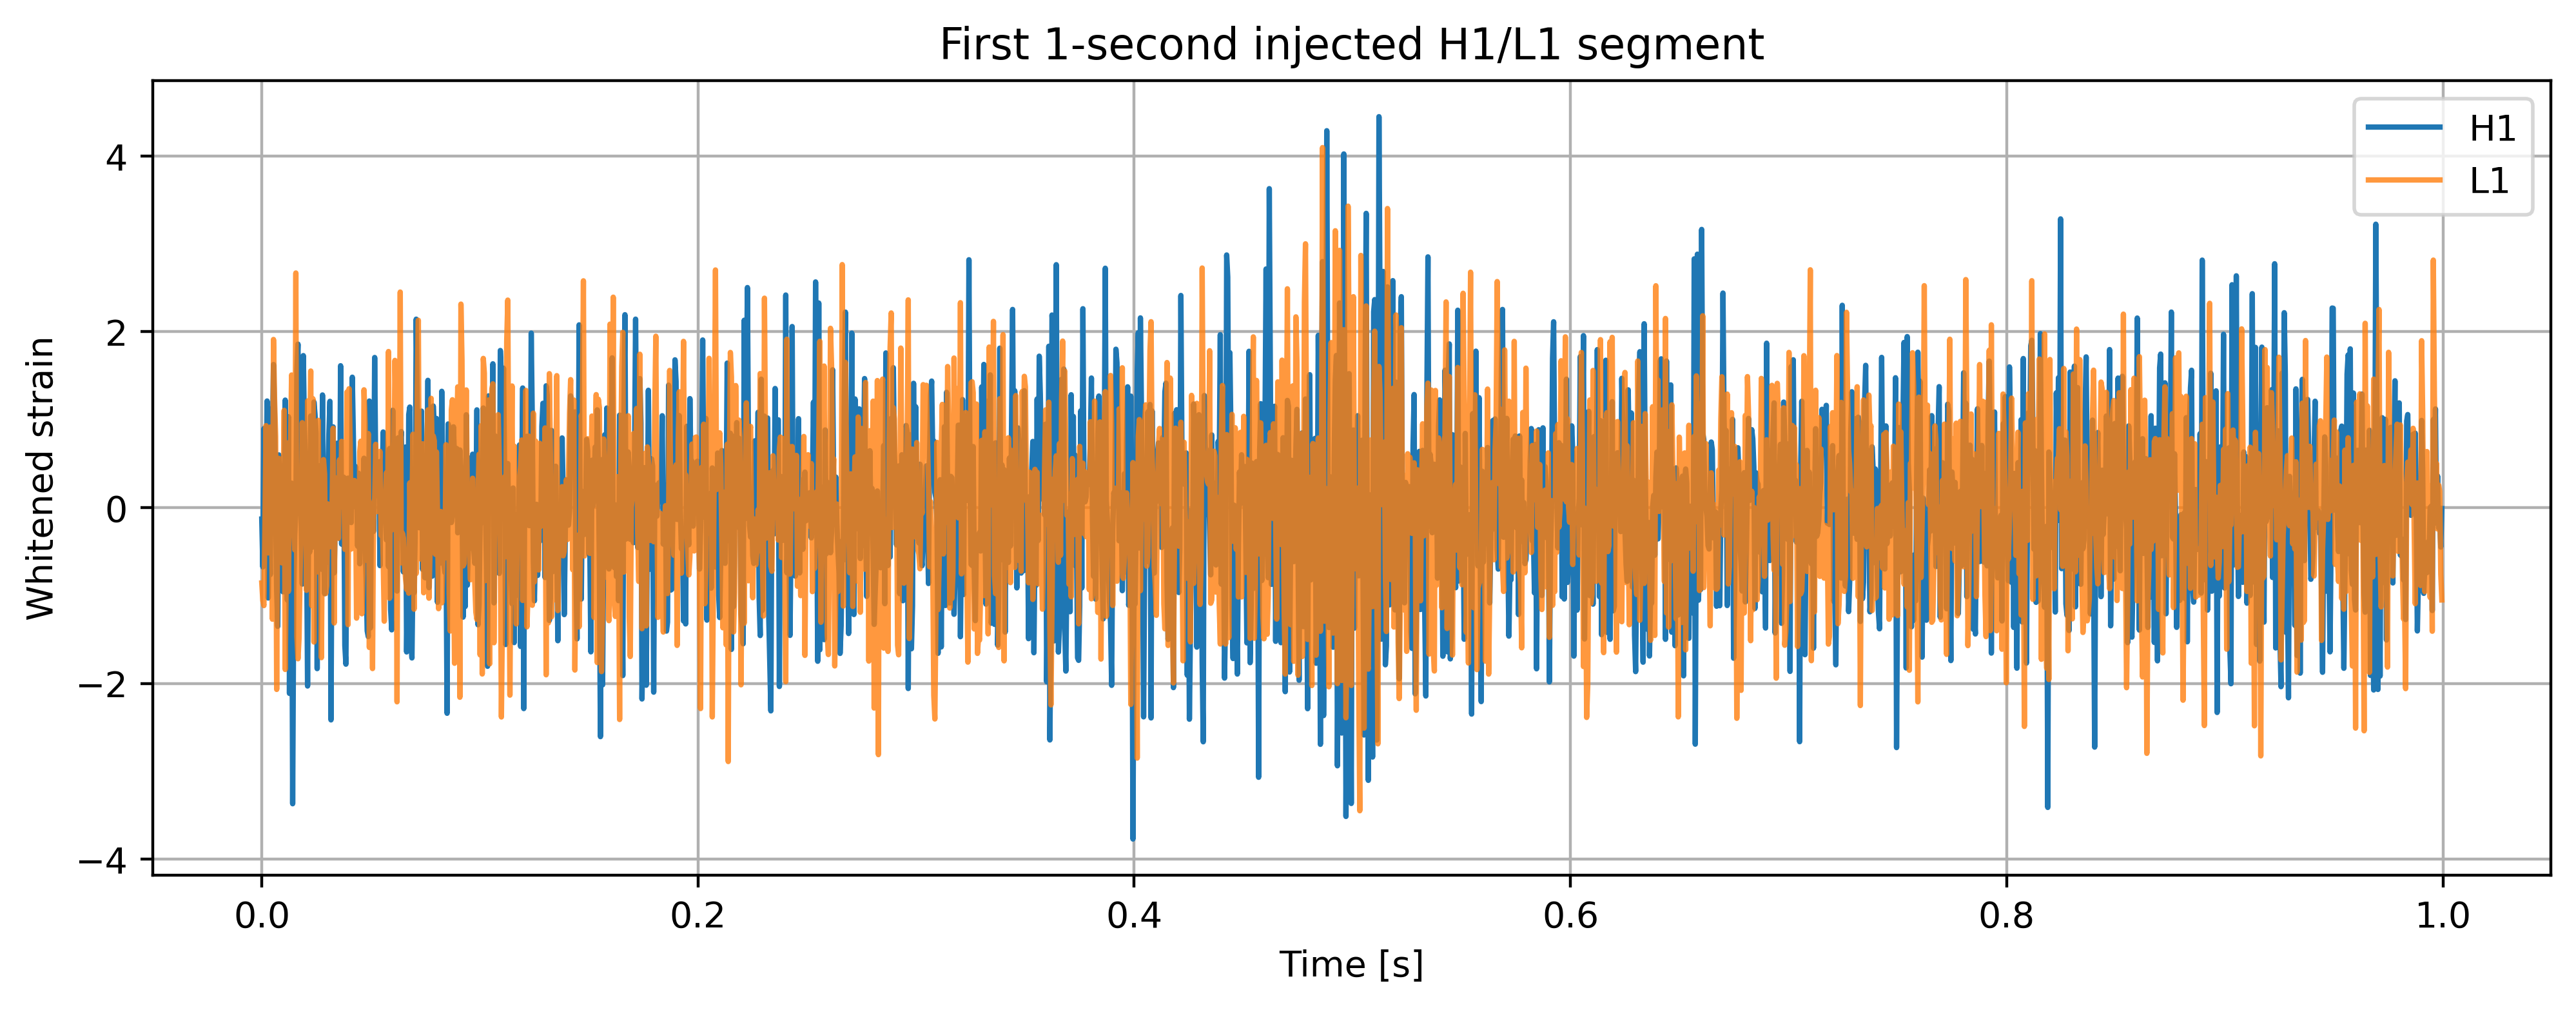

In [16]:
t1 = np.arange(2048) / fs

plt.figure(figsize=(12, 4), dpi = 400)
plt.plot(t1, H1_segments[0], label='H1')
plt.plot(t1, L1_segments[0], label='L1', alpha=0.8)
plt.xlabel('Time [s]')
plt.ylabel('Whitened strain')
plt.title('First 1-second injected H1/L1 segment')
plt.legend()
plt.grid()
plt.show()

In [17]:
# Simple dot product correlation between two arrays
def cc(x, y):
    correlation = sum(a * b for a, b in zip(x, y))
    return correlation

# Cross correlation between H1 and L1
def cross_correlation_real_detector(data1, data2, times):

    # Remove mean
    data1 = data1 - np.mean(data1)
    data2 = data2 - np.mean(data2)
    correlations = []

    # Lag range
    lags = np.arange(-len(times)//2, len(times)//2, 1)

    for lag in lags:
        data1_shifted = np.roll(data1, int(lag))
        correlation = cc(data1_shifted, data2)

        # Normalize by segment length
        correlation = correlation / len(times)
        correlations.append(correlation)

    correlations = np.array(correlations)
    return correlations, lags

In [18]:
# Build 100 testing files from injected H1 and L1 segments
# Cross-correlate the complete 1-second segments
import os
import numpy as np

save_folder = "../TranAD_MGB/data/GW_sim_500_snr15/test/"
label_folder = "../TranAD_MGB/data/GW_sim_500_snr15/labels/"

os.makedirs(save_folder, exist_ok=True)
os.makedirs(label_folder, exist_ok=True)

num_files = 100
segment_samples = 2048       # 1 second at fs = 2048 Hz
fs = int(fs)

maxccs = []
for i in range(num_files):

    # One 1-second injected H1/L1 segment
    sig1 = np.asarray(H1_segments[i]).flatten()
    sig2 = np.asarray(L1_segments[i]).flatten()

    # Remove the mean
    sig1 = sig1 - np.mean(sig1)
    sig2 = sig2 - np.mean(sig2)

    # Time array for the complete 1-second segment
    times = np.arange(segment_samples) / fs

    # Cross correlate the complete H1 and L1 segments
    final_sig, lags = cross_correlation_real_detector(sig1,sig2, times)
    final_sig = np.asarray(final_sig).flatten()
    lags = np.asarray(lags).flatten()

    # Maximum absolute cross correlation
    maxcc = np.max(np.abs(final_sig))
    maxccs.append(maxcc)

    # Save testing file
    filename = f"{i}_GW_sim_500_snr15_test.txt"
    np.savetxt(os.path.join(save_folder, filename), final_sig)

    # Create labels around the centre of the CC output
    
    labels = np.zeros((len(final_sig), 1), dtype=int)
    center_idx = len(final_sig) // 2
    signal_start = center_idx - 250
    signal_end = center_idx + 250

    # Label the central 300 samples
    labels[signal_start:signal_end, 0] = 1

    # Save label file
    label_filename = f"{i}_GW_sim_500_snr15_labels.txt"
    np.savetxt(os.path.join(label_folder, label_filename),labels,fmt="%d")
    print(f"Saved testing file: {i}")

maxccs = np.asarray(maxccs)
print("\nDone.")
print("Number of testing files:", num_files)

Saved testing file: 0
Saved testing file: 1
Saved testing file: 2
Saved testing file: 3
Saved testing file: 4
Saved testing file: 5
Saved testing file: 6
Saved testing file: 7
Saved testing file: 8
Saved testing file: 9
Saved testing file: 10
Saved testing file: 11
Saved testing file: 12
Saved testing file: 13
Saved testing file: 14
Saved testing file: 15
Saved testing file: 16
Saved testing file: 17
Saved testing file: 18
Saved testing file: 19
Saved testing file: 20
Saved testing file: 21
Saved testing file: 22
Saved testing file: 23
Saved testing file: 24
Saved testing file: 25
Saved testing file: 26
Saved testing file: 27
Saved testing file: 28
Saved testing file: 29
Saved testing file: 30
Saved testing file: 31
Saved testing file: 32
Saved testing file: 33
Saved testing file: 34
Saved testing file: 35
Saved testing file: 36
Saved testing file: 37
Saved testing file: 38
Saved testing file: 39
Saved testing file: 40
Saved testing file: 41
Saved testing file: 42
Saved testing file: 4

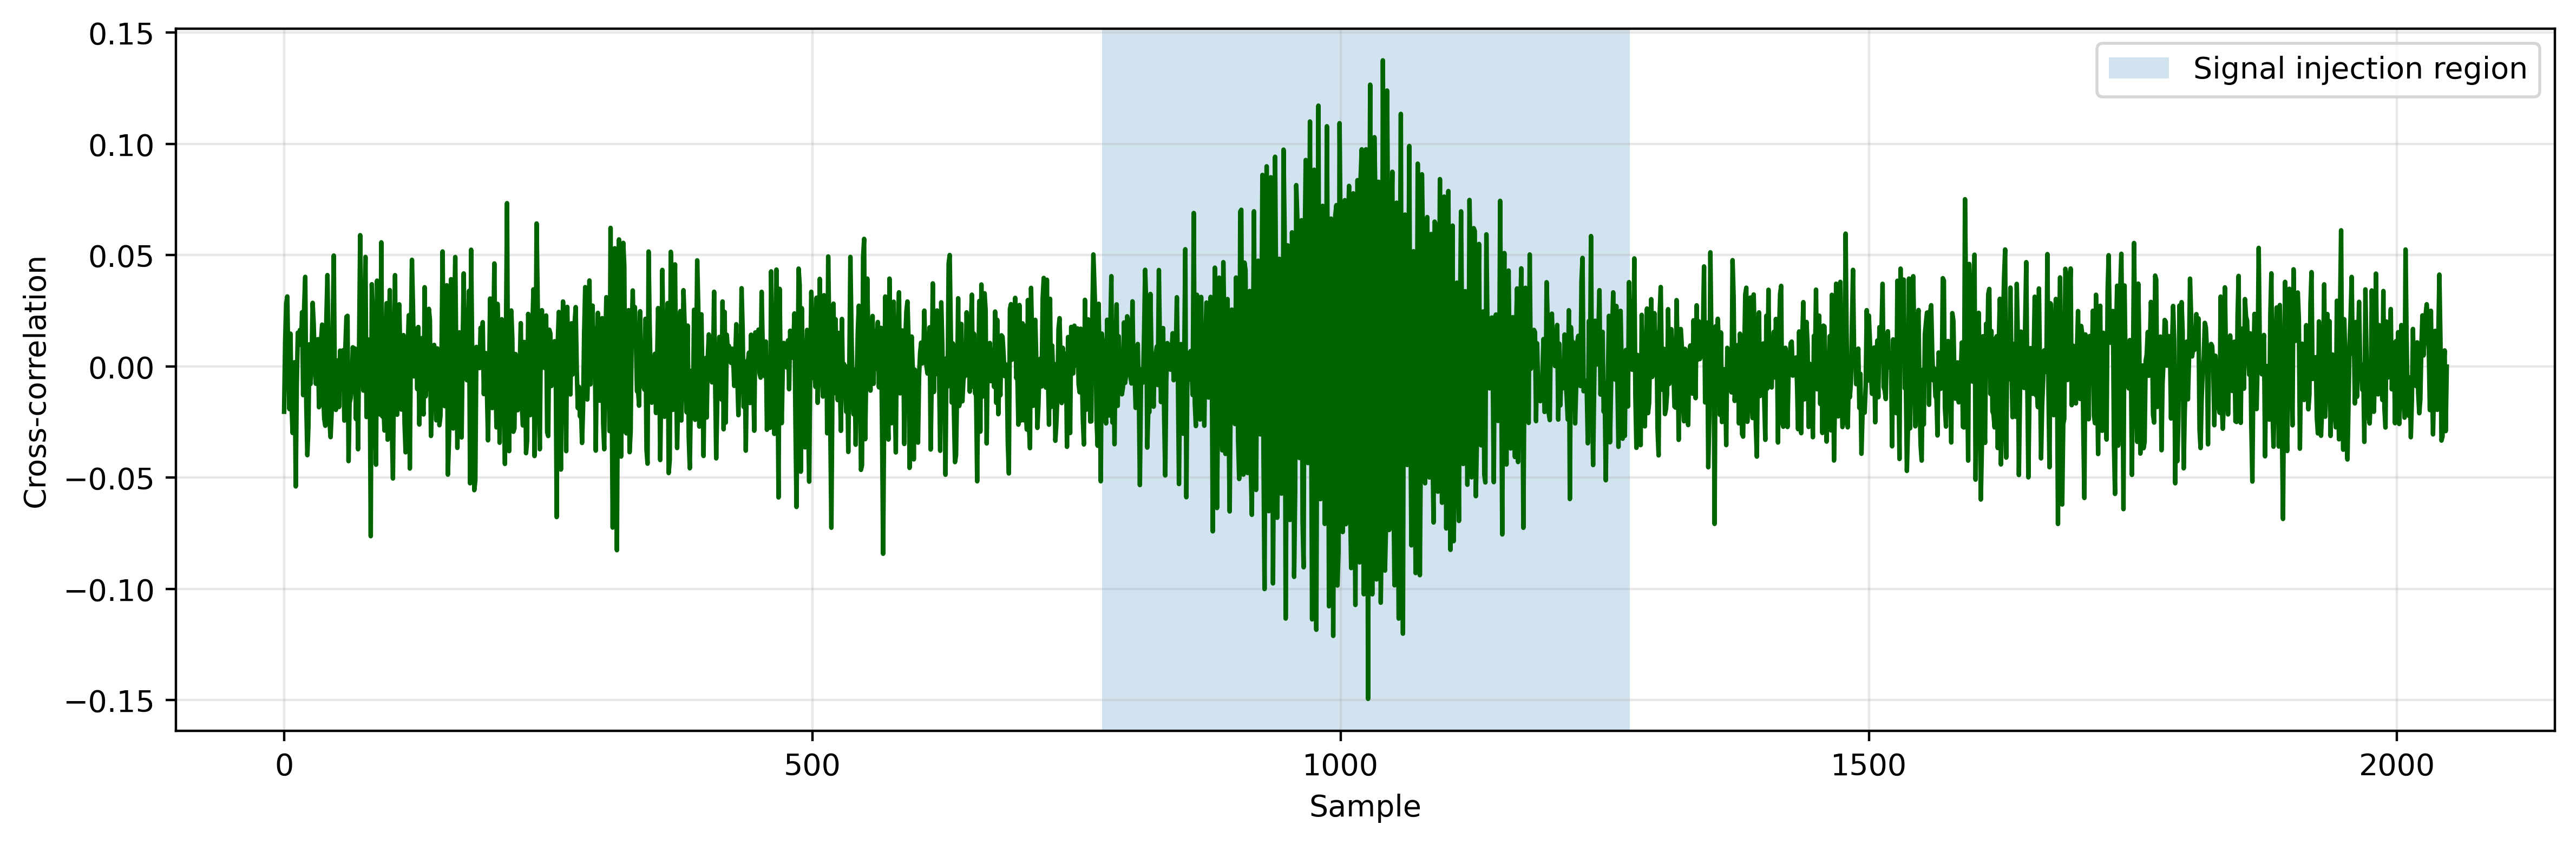

In [19]:
test_file = "../TranAD_MGB/data/GW_sim_500_snr15/test/0_GW_sim_500_snr15_test.txt"
test_data = np.loadtxt(test_file)
samples = np.arange(len(test_data))

# Injection region
center_idx = len(test_data) // 2
signal_start = center_idx - 250
signal_end   = center_idx + 250

# Plot
plt.figure(figsize=(12, 4), dpi=400)
plt.plot(samples, test_data,color = "darkgreen")
plt.axvspan(signal_start, signal_end, alpha=0.2,label="Signal injection region")
plt.xlabel("Sample")
plt.ylabel("Cross-correlation")
#plt.title("First Testing File - 900 Hz, SNR 15")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

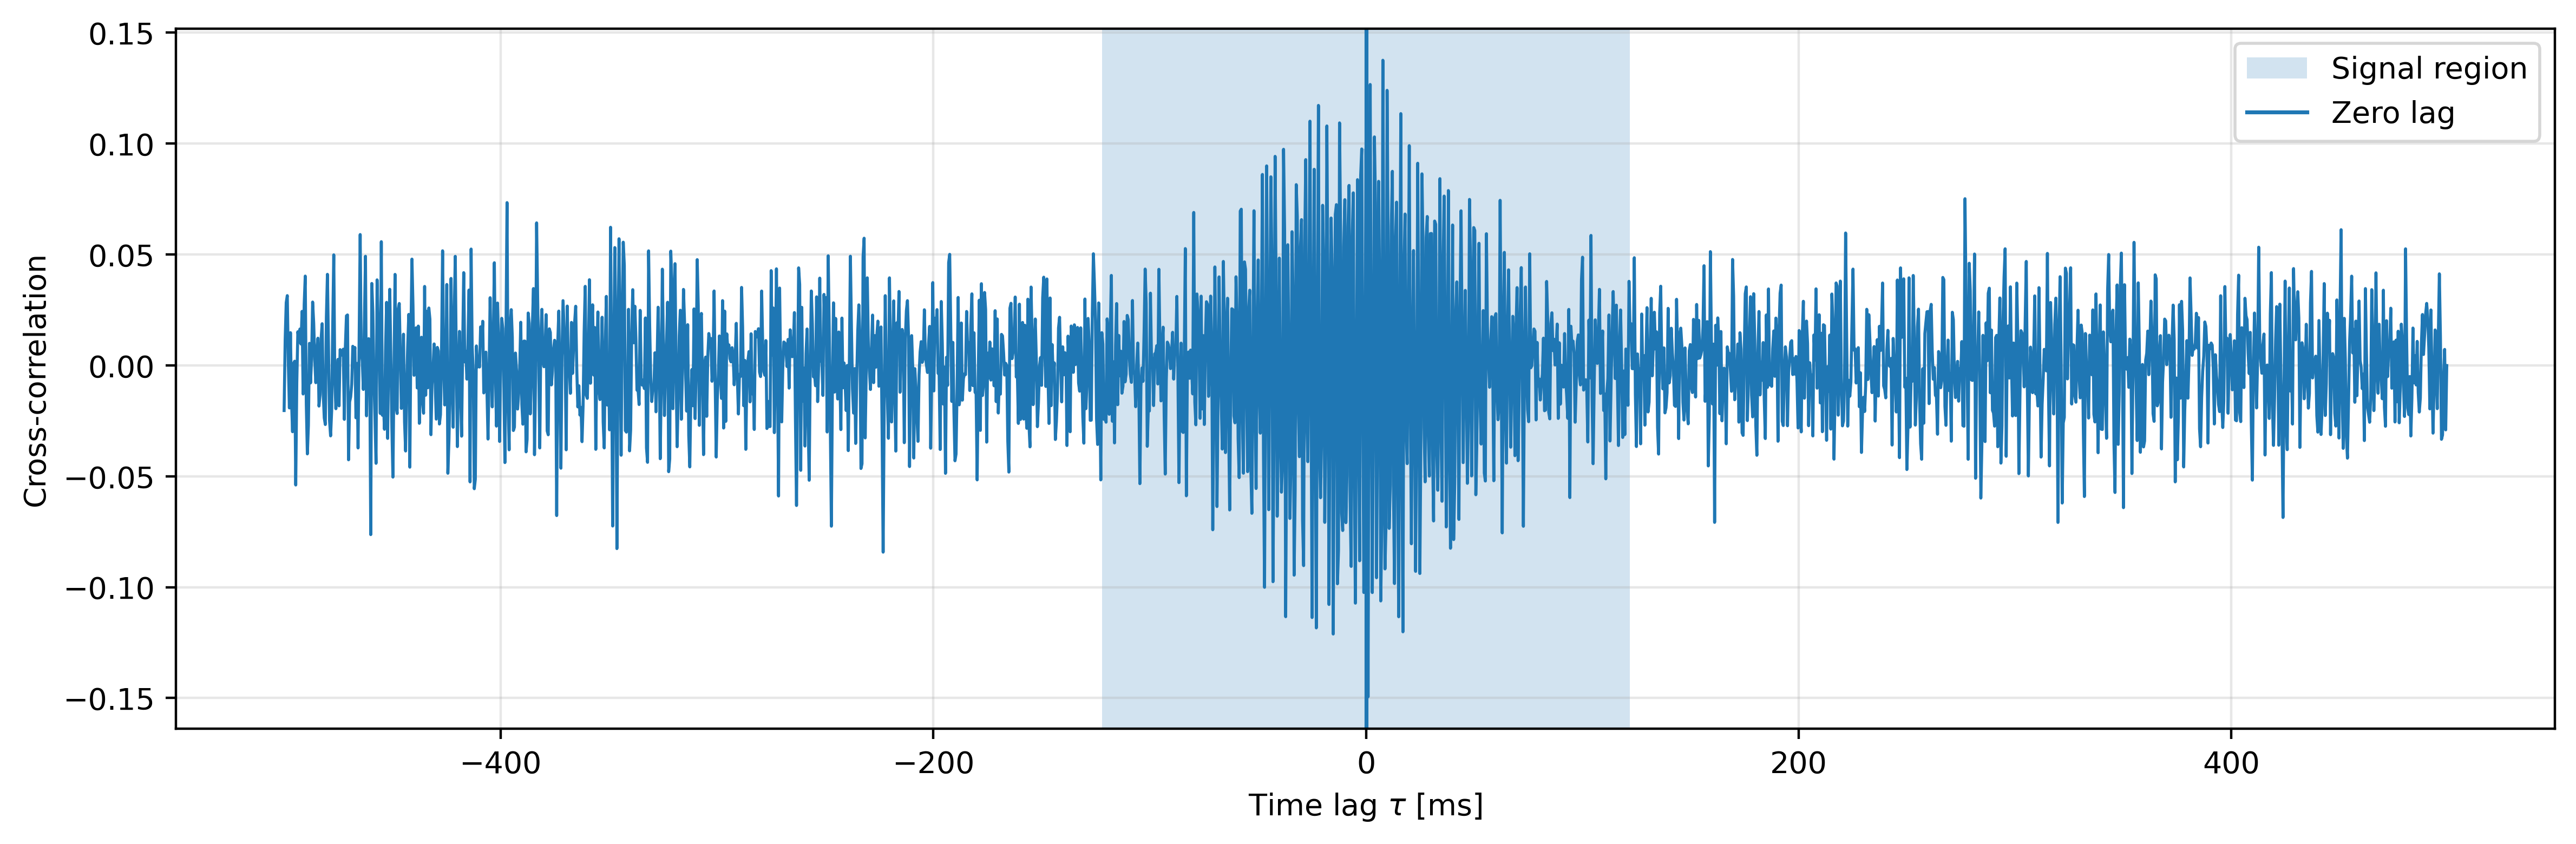

In [20]:
# ============================================================
# Plot cross-correlation versus time lag
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Load one testing cross-correlation file
test_file = "../TranAD_MGB/data/GW_sim_500_snr15/test/0_GW_sim_500_snr15_test.txt"
test_data = np.loadtxt(test_file)

# Sampling frequency
fs = 2048.0  # Hz

# Lag axis
lags_samples = np.arange(-len(test_data)//2, len(test_data)//2)
lags_ms = (lags_samples / fs) * 1000.0

# Shaded region: ±250 samples around zero lag
region_samples = 250
region_ms = (region_samples / fs) * 1000.0

# Plot
plt.figure(figsize=(12, 4), dpi=400)

plt.plot(lags_ms, test_data, linewidth=1)

# Shaded region around zero lag
plt.axvspan(
    -region_ms,
    region_ms,
    alpha=0.2,
    label="Signal region"
)

# Zero lag
plt.axvline(
    0,
    linewidth=1.3,
    label="Zero lag"
)

plt.xlabel(r"Time lag $\tau$ [ms]")
plt.ylabel("Cross-correlation")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()